# Markov Chain Monte Carlo for Posterior Sampling

*Tutorial by Yuan-Sen Ting (ting.74@osu.edu)*

*Companion material for Chapter 13 of the textbook*

*If you find this tutorial useful, please cite the accompanying textbook.*

*[Statistical Machine Learning for Astronomy](https://ui.adsabs.harvard.edu/abs/2025arXiv250612230T/abstract)*

*© 2025 Yuan-Sen Ting. All rights reserved. This tutorial may be redistributed by sharing the original [website page link](https://tingyuansen.github.io/statml/) for educational purposes. Any other reproduction or adaptation requires explicit permission from the author.*

## Introduction

Many astronomical posteriors are too complex to sample with standard methods. We infer stellar parameters from spectra, dark matter halo properties from lensing data and redshifts from photometry. The likelihood surface is often complex, and the parameter space can have many dimensions. Rejection sampling and importance sampling (Chapter 12) work poorly when a distribution has a complex shape, several modes or many dimensions.

Markov chain Monte Carlo (MCMC) does not sample the distribution directly. We construct a Markov chain, a sequence of samples in which each sample depends only on the previous one. We design the chain so that the target distribution is its equilibrium state. A long simulation of the chain then gives samples of the target, however complex it is. MCMC is widely used for Bayesian inference in astronomy. It samples posteriors that standard methods cannot handle, so it gives the uncertainties of their parameters.

In many dimensions, rejection sampling can accept far fewer samples, and importance sampling needs a good proposal distribution. MCMC avoids these problems with local steps that follow the shape of the distribution. Its price is that successive samples are correlated. An effective analysis measures this correlation and keeps its effect small.

This tutorial uses two basic algorithms, the Metropolis algorithm and Gibbs sampling. We first estimate the mean of simulated measurements with the Metropolis algorithm and judge its chains with the tools of the chapter. We then use Gibbs sampling to see how the correlation between parameters affects the sampling efficiency.

## Prerequisites and Learning Objectives

### Prerequisites

This tutorial assumes the following.

- Probability distributions, Bayes' theorem and conditional probability (Chapter 2)
- Bayesian inference, with prior distributions, likelihood functions and posterior inference (Chapters 2 and 5)
- The sampling methods, including rejection and importance sampling (Chapter 12)
- Python programming with NumPy and matplotlib
- The multivariate Gaussian distribution and its covariance matrix (Chapters 3 and 5)

### Learning Objectives

After this tutorial you can do the following.

- Implement the Metropolis algorithm and explain how the proposal width affects the sampling efficiency
- Calculate the autocorrelation of a chain and its effective sample size
- Apply the Geweke and Gelman-Rubin tests to check whether chains have reached their stationary distribution
- Recognize poor mixing and slow convergence, remove the burn-in, and check how thinning changes the effective sample size
- Implement Gibbs sampling for a problem with tractable conditional distributions

We begin by importing the libraries and setting the plot style.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# Set the plot style
plt.rcParams['figure.figsize'] = [10, 6]
plt.rcParams['font.size'] = 15
plt.rcParams['axes.labelsize'] = 15
plt.rcParams['axes.titlesize'] = 16
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['legend.fontsize'] = 15
plt.rcParams['legend.frameon'] = False
plt.rcParams['axes.prop_cycle'] = plt.cycler(color=['#3468A8', '#E49A3A', '#2E8B6E', '#C24A3E', '#6F5E9E', '#8A8A8A'])
plt.rcParams.update({'font.family': 'serif', 'font.serif': ['DejaVu Serif'], 'mathtext.fontset': 'cm'})
plt.rcParams.update({'xtick.direction': 'in', 'ytick.direction': 'in', 'xtick.top': True, 'ytick.right': True})

# Set the random seed for reproducibility
np.random.seed(42)

%matplotlib inline

## The Metropolis Algorithm

The Metropolis algorithm samples a probability distribution that we can evaluate only up to a constant. It needs only the ratio of two probabilities. We therefore do not need the normalization constant that makes many inference problems in astronomy hard.

### The Intuition

Recall the explorer of Chapter 13 who wants to map the population distribution of Columbus, Ohio. Each day a guidebook suggests a nearby neighborhood, and the explorer compares its population density with that of the current one. A denser neighborhood is always chosen, and a less dense one is chosen with a probability equal to the ratio of the densities. Otherwise the explorer stays for another day. The record of the visits then follows the population density. In the Metropolis algorithm the population density is the probability density, and the record of the visits is a sample of the distribution.

### Mathematical Basis

Two conditions make the chain converge to our target distribution $p$. The first is detailed balance (Section 13.2),

$$p(\mathbf{x}) T(\mathbf{x}, \mathbf{x}') = p(\mathbf{x}') T(\mathbf{x}', \mathbf{x}),$$

where $T(\mathbf{x}, \mathbf{x}')$ is the transition probability from state $\mathbf{x}$ to state $\mathbf{x}'$. The left side is the flow of probability from $\mathbf{x}$ to $\mathbf{x}'$, and the right side is the flow in the reverse direction. When the two flows are equal, one step of the chain leaves $p$ unchanged, so $p$ is the stationary distribution of the chain.

The second condition is ergodicity (Section 13.5). The chain must be irreducible, so that every state can reach every other state. It must be positive recurrent, so that it returns to each state in a finite expected time. It must also be aperiodic, so that it has no cycles. The chain then does not stay in disconnected regions. We typically have ergodicity in practice, and detailed balance and ergodicity together make the chain converge to $p$.

### The Metropolis Algorithm: Step by Step

The Metropolis algorithm uses a symmetric proposal distribution, $q(\mathbf{x}'|\mathbf{x}) = q(\mathbf{x}|\mathbf{x}')$, and a transition probability that satisfies detailed balance. The transition probability is $T(\mathbf{x}, \mathbf{x}') = q(\mathbf{x}'|\mathbf{x})A(\mathbf{x}, \mathbf{x}')$, where $A$ is the acceptance probability,

$$A(\mathbf{x}, \mathbf{x}') = \min\left(1, \frac{p(\mathbf{x}'|\mathcal{D})}{p(\mathbf{x}|\mathcal{D})}\right),$$

and $\mathcal{D}$ is the data. More generally, the Metropolis-Hastings algorithm allows an asymmetric proposal and multiplies the ratio by $q(\mathbf{x}|\mathbf{x}')/q(\mathbf{x}'|\mathbf{x})$ (Section 13.14). We always accept a move to a region of higher probability. We accept a move to a region of lower probability with a probability equal to the ratio of the two posteriors. Section 13.3 checks that this rule satisfies detailed balance.

The algorithm depends only on probability ratios. The posterior is proportional to the likelihood times the prior, $p(\mathbf{x}|\mathcal{D}) \propto p(\mathcal{D}|\mathbf{x})p(\mathbf{x})$. We can therefore compute the ratio without the normalization constant,

$$\frac{p(\mathbf{x}'|\mathcal{D})}{p(\mathbf{x}|\mathcal{D})} = \frac{p(\mathcal{D}|\mathbf{x}')p(\mathbf{x}')}{p(\mathcal{D}|\mathbf{x})p(\mathbf{x})}.$$

The implementation follows these steps.

1. **Initialize.** Choose a starting point $\mathbf{x}^{(0)}$ in parameter space.

2. **Iterate.** For $t = 1, 2, \ldots, N$, where $N$ is the number of iterations, do the following.
   - **Propose.** Generate $\mathbf{x}' \sim q(\mathbf{x}'|\mathbf{x}^{(t-1)})$.
   - **Accept or reject.** With probability $A(\mathbf{x}^{(t-1)}, \mathbf{x}')$, set $\mathbf{x}^{(t)} = \mathbf{x}'$. Otherwise set $\mathbf{x}^{(t)} = \mathbf{x}^{(t-1)}$.

3. **Return.** The sequence $\{\mathbf{x}^{(0)}, \mathbf{x}^{(1)}, \ldots, \mathbf{x}^{(N)}\}$.

## Estimating the Sample Mean

We apply the Metropolis algorithm to a concrete problem, the estimation of the mean of a population from noisy measurements. This problem has one parameter, so it is a good test for MCMC before we turn to harder problems.

### The Statistical Model

We observe 1000 measurements $\{x_i\}$ from a normal distribution with unknown mean $\mu$ and known standard deviation $\sigma = 1$. We simulate them with a true mean of 1. Examples of this setup are the mean radial velocity of a star cluster and the systematic offset in photometric measurements.

In the notation of the previous section, the state $\mathbf{x}$ is the parameter $\mu$ and the data $\mathcal{D}$ are the measurements $\{x_i\}$. In Bayesian terms, we seek the posterior distribution

$$p(\mu | \{x_i\}) \propto p(\{x_i\} | \mu) \times p(\mu).$$

For independent observations from a normal distribution, the likelihood is

$$p(\{x_i\} | \mu) = \prod_{i=1}^{1000} \frac{1}{\sqrt{2\pi}} \exp\left(-\frac{(x_i - \mu)^2}{2}\right).$$

We use a Cauchy prior for $\mu$, which has heavier tails than a normal distribution,

$$p(\mu) = \frac{1}{\pi\gamma} \frac{1}{1 + \left(\frac{\mu-\mu_0}{\gamma}\right)^2},$$

where $\mu_0 = 0$ is the location parameter and $\gamma = 3$ is the scale parameter. The heavy tails allow large values of $\mu$. The Cauchy prior is therefore useful when we know little about the range of the parameter.

The product of 1000 likelihood factors is too small for a floating-point number. We therefore work with the logarithm of the posterior,

$$\ln p(\mu | \{x_i\}) = \sum_{i=1}^{1000} \ln p(x_i | \mu) + \ln p(\mu) + \text{const}.$$

We now simulate the 1000 measurements and print their sample mean.

In [2]:
# Define the number of measurements and the true mean
n = 1000
loc_true = 1

# Simulate measurements from a normal distribution with a standard deviation of one
x_sample = np.random.normal(loc=loc_true, scale=1, size=n)

# Print the sample mean
print(f"Sample mean = {np.mean(x_sample):.4f}")

Sample mean = 1.0193


The histogram shows the simulated sample with the true mean and the sample mean.

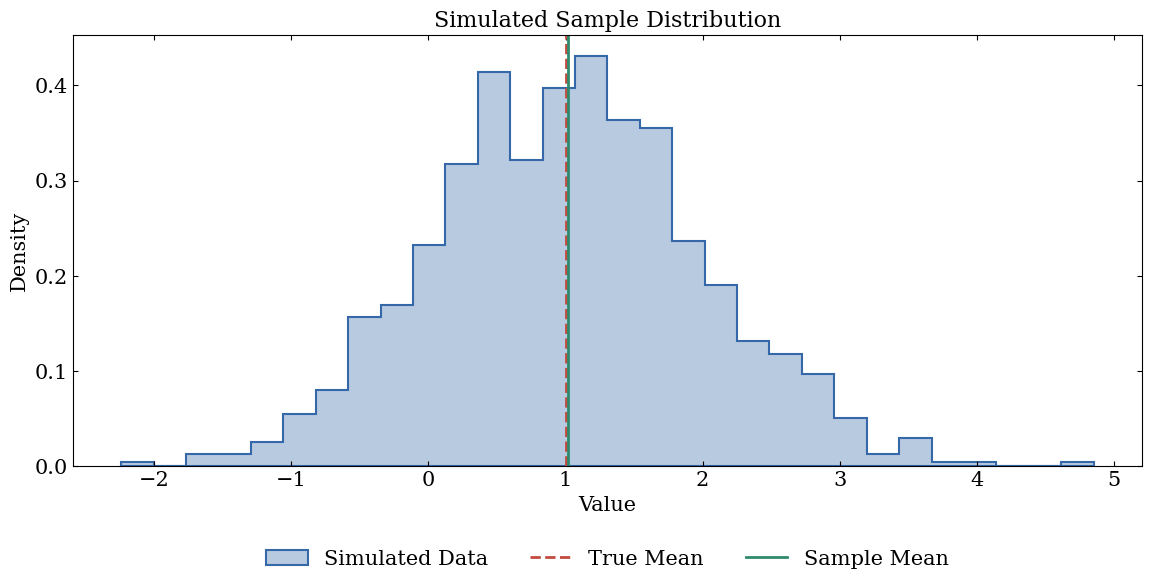

In [3]:
# Visualize the sample
plt.figure(figsize=(13.8, 5.6))
plt.hist(x_sample, bins=30, density=True, label='Simulated Data',
         histtype='stepfilled', facecolor=('C0', 0.35), edgecolor='C0', linewidth=1.5)
plt.axvline(x=loc_true, color='C3', linestyle='--', linewidth=2, label='True Mean')
plt.axvline(x=np.mean(x_sample), color='C2', linestyle='-', linewidth=2, label='Sample Mean')
plt.xlabel('Value')
plt.ylabel('Density')
plt.title('Simulated Sample Distribution')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.show()

The sample mean is a little above the true mean, because the measurements have noise. The posterior should therefore center near the sample mean and not exactly at the true mean.

### Implementing the Log-Posterior Function

The first step of the implementation is the log-posterior function. It sums two terms. The log likelihood measures how well a proposed mean $\mu$ explains the data. The log prior encodes our prior beliefs about plausible values of $\mu$.

In [4]:
def log_posterior(mu, x_sample):
    """Return the log posterior of the mean mu, up to a constant."""

    # Log likelihood (normal distribution with known standard deviation 1)
    log_likelihood = -0.5 * np.sum((x_sample - mu) ** 2) - 0.5 * len(x_sample) * np.log(2 * np.pi)

    # Log prior (Cauchy distribution)
    log_prior = -np.log(np.pi * 3 * (1 + (mu / 3) ** 2))

    # Log posterior (up to a constant)
    return log_likelihood + log_prior

The function takes a value of $\mu$ and the data and returns the log posterior up to a constant. The Metropolis algorithm calls it at every step.

### The Proposal Mechanism

The proposal distribution decides how the chain moves through parameter space, so it sets the sampling efficiency. We use a normal distribution centered at the current value of $\mu$. Its standard deviation $\nu$, the proposal width, controls the step size,

$$q(\mu' | \mu) = \mathcal{N}(\mu' | \mu, \nu^2).$$

This is the Gaussian proposal of the chapter, with the covariance matrix $\boldsymbol{\Sigma}$ reduced to the number $\nu^2$. This proposal is symmetric, $q(\mu' | \mu) = q(\mu | \mu')$, so the Metropolis algorithm applies. The width $\nu$ is a tuning choice. If $\nu$ is too small, the chain accepts most steps but moves slowly. If $\nu$ is too large, most proposals land in regions of low probability and are rejected.

### Implementing the Metropolis Algorithm

The function below runs the algorithm for a given number of iterations and counts the accepted proposals. The acceptance rate gives feedback on the width $\nu$. A very high rate suggests that the steps are too small, and a very low rate suggests that they are too large. For random walk proposals, rates of about 20 to 40 percent tend to be the most efficient (Section 13.9).

In [5]:
def metropolis(mu_init, nu, n_iterations):
    """Run the Metropolis algorithm and return the chain and the acceptance rate in percent."""

    # Initialize the chain with the starting value
    chain = [mu_init]
    mu = mu_init
    accept_count = 0

    # Run the chain
    for i in range(n_iterations):
        # Propose a new value from a normal distribution centered at mu
        mu_star = np.random.normal(mu, nu)

        # Compute the acceptance probability (the ratio in log space)
        log_ratio = log_posterior(mu_star, x_sample) - log_posterior(mu, x_sample)
        alpha = min(1, np.exp(log_ratio))

        # Accept or reject
        u = np.random.uniform()
        if u < alpha:
            mu = mu_star
            accept_count += 1

        # Add the current state to the chain
        chain.append(mu)

    # Acceptance rate in percent
    accept_rate = accept_count / n_iterations * 100

    return chain, accept_rate

The function returns the whole chain and its acceptance rate in percent. We now run it for three proposal widths.

The posterior of $\mu$ is narrow, because 1000 measurements fix the mean well. Its standard deviation is close to the standard error of the mean, $\sigma/\sqrt{N} = 1/\sqrt{1000} \approx 0.03$ (Section 3.6). This is the sampling noise of an average. The mean of $N$ noisy measurements scatters by $\sigma/\sqrt{N}$ around the true mean, because the noise partly cancels.

We run the algorithm with three proposal widths, $\nu = 0.01$, 0.1 and 0.5. They are one third, 3 times and 16 times this scale. Each chain has 10,000 iterations and starts at $\mu_{\text{init}} = 0$, about 30 standard errors away, so its first samples do not follow the posterior. We call this early stretch the burn-in.

In [6]:
# Define the parameters of the experiment
nu_values = [0.01, 0.1, 0.5]
mu_init = 0
n_iterations = 10000
results = {}

# Run the Metropolis algorithm for each proposal width
for nu in nu_values:
    chain, accept_rate = metropolis(mu_init, nu, n_iterations)
    results[nu] = (chain, accept_rate)

### Visualizing the Chains

We plot the first 1000 samples of each chain. The trace plots show the value of each chain against the iteration, so they show how quickly the chain reaches the posterior. They also show how well it mixes, which means how quickly it moves through the region of high probability. Each panel gives the acceptance rate of its chain.

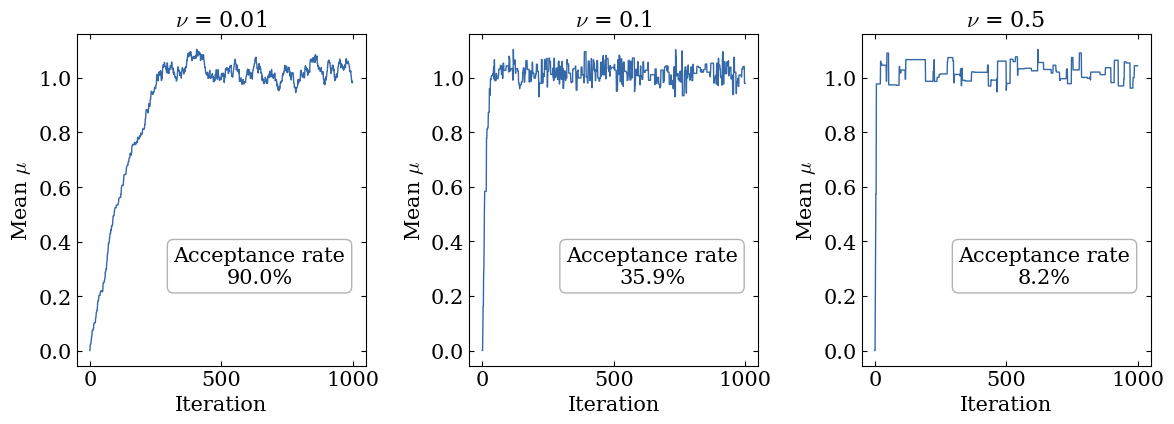

In [7]:
# Create a figure with three subplots, one for each value of nu
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))

# For each value of nu, plot the first 1000 samples of the chain
for index, nu in enumerate(nu_values):
    ax = axes[index]
    chain, accept_rate = results[nu]
    ax.plot(chain[:1000], linewidth=1)

    # Add labels and title
    ax.set_title(f"$\\nu$ = {nu}")
    ax.set_xlabel("Iteration")
    ax.set_ylabel("Mean $\\mu$")

    # Add the acceptance rate as text in the plot
    ax.text(0.93, 0.3, f"Acceptance rate\n{accept_rate:.1f}%", ha='right', va='center', multialignment='center',
            transform=ax.transAxes,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="0.7"))

plt.tight_layout()
plt.show()

The three widths give different chains.

- **Small $\nu = 0.01$.** The chain climbs slowly from its starting value and reaches the posterior after about 250 iterations. Almost every proposal is accepted, because a tiny step stays close to the current state. Consecutive samples are highly correlated and give little new information.
- **Medium $\nu = 0.1$.** The chain reaches the posterior quickly. It then moves between states with moderate jumps and covers the range of plausible values.
- **Large $\nu = 0.5$.** The chain reaches the posterior within a few iterations. It then stays at the same value for long stretches and only occasionally jumps to a new value, because most proposals are rejected.

We discard the burn-in (Section 13.13). The traces show that all three chains have reached the posterior by iteration 500, so we discard the first 500 iterations of each chain. The convergence tests below check this choice.

### Autocorrelation and Effective Sample Size

We now quantify these observations with the autocorrelation of the chains. Successive samples of an MCMC chain are correlated, because each new state depends on the previous one. For a sequence of samples $\{X_0, X_1, X_2, \ldots\}$, the autocorrelation at lag $k$ measures how correlated two samples are that are $k$ steps apart (Section 13.10),

$$R(k) = \frac{\mathbb{E}[(X_t - \mu_X)(X_{t+k} - \mu_X)]}{\sigma_X^2},$$

where $\mu_X$ and $\sigma_X^2$ are the mean and the variance of the stationary distribution. Independent samples have $R(k) = 0$ for all $k > 0$. For MCMC samples, $R(k)$ typically decays as the lag increases, and the decay rate decides how many samples we need for reliable estimates.

The effective sample size (ESS) is the number of independent samples that carry the same information as our correlated chain (Section 13.11),

$$\text{ESS} = \frac{N}{1 + 2\sum_{k=1}^{\infty}R(k)},$$

where $N$ is the number of samples in the chain. A chain with a high autocorrelation has an ESS far below $N$. In practice we estimate $R(k)$ from the chain and sum it only up to lag 100, because the estimate becomes noisy at large lags.

Computing $R(k)$ at every lag directly takes $O(N^2)$ operations. The chapter therefore uses the fast Fourier transform (FFT), but it only states the method (Section 13.10). We therefore introduce the Fourier transform first.

#### The Fourier Transform and the Autocorrelation

**The Fourier transform.** A chain of $M$ numbers $x_0, \ldots, x_{M-1}$ can be written as a sum of sinusoids. The discrete Fourier transform gives the amount of each sinusoid,

$$\tilde{x}_f = \sum_{t=0}^{M-1} x_t\, e^{-2\pi i f t/M}, \qquad f = 0, 1, \ldots, M-1.$$

Here $i$ is the imaginary unit, and $e^{-2\pi i f t/M} = \cos(2\pi f t/M) - i \sin(2\pi f t/M)$ is a sinusoid that completes $f$ cycles over the $M$ samples. The number $\tilde{x}_f$ is large when the chain oscillates with $f$ cycles and small when it does not. The inverse transform recovers the chain, so no information is lost,

$$x_t = \frac{1}{M}\sum_{f=0}^{M-1} \tilde{x}_f\, e^{2\pi i f t/M}.$$

**The power spectrum.** The squared magnitude $|\tilde{x}_f|^2 = \tilde{x}_f \tilde{x}_f^*$ is the power spectrum, where the star is the complex conjugate. It shows how much of the variation of the chain sits at each frequency.

**The Wiener-Khinchin theorem.** Let $x_t$ be the centered chain of $N$ samples, padded with $N$ zeros so that $M = 2N$. Define $C(k)$ as the sum of the products of samples $k$ steps apart, with $C(-k) = C(k)$ and $x_t = 0$ beyond the chain,

$$C(k) = \sum_{t} x_t\, x_{t+k}.$$

The theorem says that the power spectrum is the Fourier transform of $C(k)$,

$$|\tilde{x}_f|^2 = \sum_{k=-(N-1)}^{N-1} C(k)\, e^{-2\pi i f k/M}.$$

We do not prove it here. The squared magnitude is a double sum over pairs of samples, and the phase of each pair depends only on the lag between them. Collecting the pairs by lag gives $C(k)$. The inverse transform of the power spectrum therefore returns $C(k)$ at every lag at once.

The padding matters, because the transform treats the chain as periodic. With $2N$ points, the lags from $-(N-1)$ to $N-1$ do not overlap, so the end of the chain does not wrap around to its start.

**From $C(k)$ to $R(k)$.** The autocovariance $C(k)/N$ is the average product of samples $k$ steps apart. At lag 0 it is the variance of the chain. Dividing by it gives $R(k) = C(k)/C(0)$, so that $R(0) = 1$.

**The fast Fourier transform.** Each value $\tilde{x}_f$ is a sum of $M$ terms, so the definition needs $O(M^2)$ operations for all frequencies. This is as slow as the direct sums of products. The FFT gives the same values in $O(M \log M)$ operations by reusing partial sums. The route through the power spectrum needs one transform and one inverse transform, so it costs $O(N \log N)$.

**The steps.** The function below follows four steps.

1. **Center.** Subtract the mean of the chain, so that the products measure deviations from the mean.
2. **Transform.** Pad the chain with $N$ zeros and take its Fourier transform with the FFT.
3. **Power spectrum.** Multiply the transform by its complex conjugate.
4. **Invert.** The inverse transform gives $C(k)$. We divide by $N$ for the autocovariance and by its value at lag 0 for $R(k)$.

We write one function for these steps, one that plots $R(k)$ with a 95 percent band, and one that returns the ESS.

In [8]:
def autocorrelation(x, nlags):
    """Return the autocorrelation of a chain at the lags 0 to nlags, computed with the FFT."""

    # Step 1. Subtract the mean of the chain
    x = np.asarray(x) - np.mean(x)
    n = len(x)

    # Step 2. Fourier transform of the chain padded with n zeros (rfft is the FFT of a real sequence)
    transform = np.fft.rfft(x, 2 * n)

    # Step 3. Power spectrum, the squared magnitude of the transform
    power_spectrum = transform * np.conj(transform)

    # Step 4. Inverse transform of the power spectrum gives C(k) at every lag, and C(k)/n is the autocovariance
    covariance = np.fft.irfft(power_spectrum)[:nlags + 1] / n

    # Divide by the variance, so that lag 0 gives 1
    return covariance / covariance[0]

def plot_autocorrelation(x, lags, ax):
    """Plot the autocorrelation with the 95 percent band of independent samples."""
    acf_values = autocorrelation(x, lags)

    # For independent samples the autocorrelation has a standard deviation of about 1/sqrt(N)
    # and 1.96 standard deviations (close to 2 sigma) contain 95 percent of a normal distribution
    half_width = 1.96 / np.sqrt(len(x))

    # Stems and dots for the autocorrelation, and the band around zero in red
    lag_values = np.arange(lags + 1)
    ax.vlines(lag_values, 0, acf_values)
    ax.axhline(0)
    ax.margins(0.05)
    ax.plot(lag_values, acf_values, marker='o', markersize=5, linestyle='None')
    ax.axhspan(-half_width, half_width, color='C3', alpha=0.4)
    ax.axhline(half_width, color='C3', linestyle='--', linewidth=1)
    ax.axhline(-half_width, color='C3', linestyle='--', linewidth=1)

def calculate_ess(samples):
    """Return the effective sample size from the autocorrelation up to lag 100."""
    N = len(samples)

    # Autocorrelation up to lag 100
    autocorr_values = autocorrelation(samples, 100)

    # ESS = N / (1 + 2 * sum of the autocorrelation over lags 1 to 100)
    return N / (1 + 2 * sum(autocorr_values[1:]))

The functions give $R(k)$ of a chain, plot it, and return the ESS from the sum of $R(k)$ up to lag 100.

We now plot the autocorrelation function of each chain after the burn-in. Each panel gives the acceptance rate and the ESS of its chain.

The red band marks the scatter of the estimated autocorrelation around zero for independent samples. At a lag $k > 0$, the estimate is the average of $N$ products of two independent samples, each with mean 0 and variance 1. Each product has mean 0 and variance 1, so the average has a standard error of $1/\sqrt{N}$ (Section 3.6). By the central limit theorem (Section 2.3), the average is also nearly normal. A normal distribution has 95 percent of its probability within 1.96 standard deviations, close to $2\sigma$, so the band is $\pm 1.96/\sqrt{N}$.

We want the autocorrelation to fall into the band quickly. Inside the band, samples $k$ steps apart cannot be told from independent samples, so the chain has forgotten where it was $k$ steps earlier. The lag where the autocorrelation enters the band is roughly the number of steps that the chain needs for a new, nearly independent sample. The band is narrow because $N$ is large, so only a small autocorrelation counts as zero.

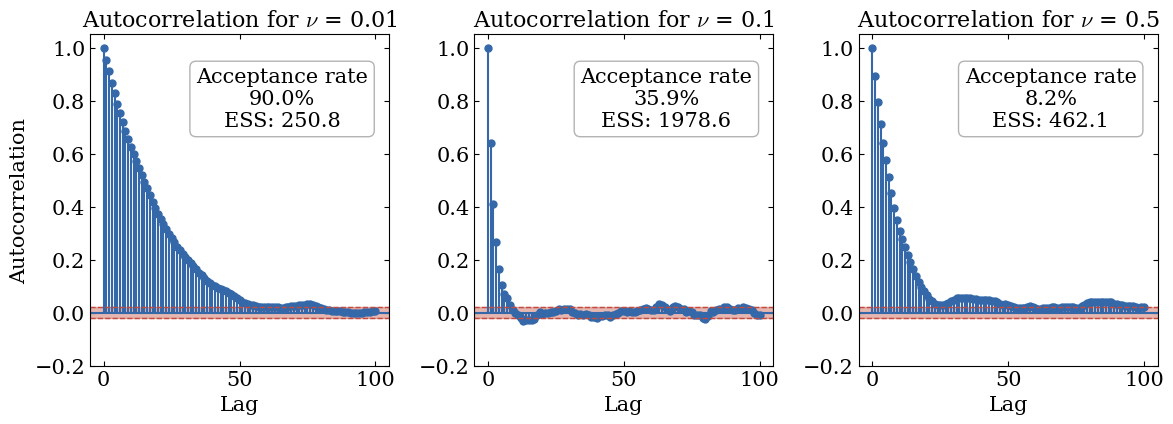

In [9]:
# Create a figure for the autocorrelation plots
fig, axes = plt.subplots(1, 3, figsize=(12, 4.5))

for index, nu in enumerate(nu_values):
    ax = axes[index]
    chain, accept_rate = results[nu]

    # Discard the first 500 samples as burn-in
    chain = chain[500:]

    # Plot the autocorrelation function
    plot_autocorrelation(chain, 100, ax)
    ax.set_ylim(-0.2, 1.05)
    ax.set_title(f"Autocorrelation for $\\nu$ = {nu}")
    ax.set_xlabel("Lag")

    if index == 0:
        ax.set_ylabel("Autocorrelation")

    # Calculate the effective sample size and display it with the acceptance rate
    ess = calculate_ess(chain)
    ax.text(0.93, 0.9, f"Acceptance rate\n{accept_rate:.1f}%\nESS: {ess:.1f}", ha='right', va='top', multialignment='center',
            transform=ax.transAxes,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="0.7"))

plt.tight_layout()
plt.show()

The autocorrelation functions differ as the trace plots suggest.

- **Small $\nu = 0.01$.** The autocorrelation decays slowly and stays outside the band for tens of lags. Samples that are many iterations apart still hold redundant information, so the ESS is far below the number of samples.
- **Medium $\nu = 0.1$.** The autocorrelation falls close to the band after a few lags, so the chain forgets its past quickly. The ESS is the largest of the three, so this is our most efficient sampler.
- **Large $\nu = 0.5$.** The rejected proposals leave the chain in place, so the autocorrelation starts high. The ESS lies between those of the small and the medium width.

As a rule of thumb, an ESS above 100 is enough to estimate a mean and a standard deviation (Section 13.11). All three chains meet this rule, but the ESS of the medium chain is several times that of the narrow chain.

The narrow chain accepts the most proposals but has the lowest ESS, so a high acceptance rate alone does not make an efficient chain. We must tune the proposal width to balance the acceptance rate and the mixing. The medium width has an acceptance rate between 20 and 40 percent and a rapid decay of the autocorrelation, and it gives the largest ESS.

### Convergence Diagnostics

The ESS assumes that a chain follows the posterior. Before we use the samples for inference, we must therefore check that the chains have converged to their stationary distribution. We judged the traces by eye. This is easy for one parameter and hard for many parameters, so we also use statistical tests (Section 13.13).

#### The Geweke Test

The Geweke test compares the means of two segments of one chain. Segment A is the first 10 percent and segment B is the last 50 percent. If the chain has converged, both segments sample the same distribution, so their means agree. The function below has four steps.

1. **Segments and means.** Take the first and the last part of the chain, and calculate the mean $\bar{x}$ of each.
2. **Autocorrelation.** Correlated samples make a mean less certain than independent samples do. We therefore calculate $R(k)$ of each segment with our autocorrelation function.
3. **Variance of the mean.** For $N$ independent samples, the variance of the mean is $\hat{\sigma}^2/N$ (Section 3.6). A correlated segment holds only ESS independent samples, so the variance is larger, $\hat{\sigma}^2/\text{ESS}$. The ESS formula turns this into the expression below. A window lowers the weight of the noisy high lags in the sum, which stops at a maximum lag $l$.
4. **Z-score.** The difference of the two means divided by its standard error gives $Z$.

For a segment of $N$ samples with sample variance $\hat{\sigma}^2$, the variance of its mean is

$$\hat{S} = \frac{\hat{\sigma}^2}{N}\left(1 + 2\sum_{k=1}^{l} w(k)\, R(k)\right), \quad w(k) = 1 - \frac{k}{l}.$$

The Z-score of the two segments A and B is then

$$Z = \frac{\bar{x}_A - \bar{x}_B}{\sqrt{\hat{S}_A + \hat{S}_B}}.$$

We consider the chain converged if $|Z| < 2$, which contains about 95 percent of a standard normal distribution.

In [10]:
def geweke_test(chain, first=0.1, last=0.5, max_lag=20):
    """Return the Geweke Z-score of a chain from its first and last segments."""
    n = len(chain)

    # Step 1. Define the segments and calculate their means
    n_a = int(first * n)
    n_b = int(last * n)

    segment_a = chain[:n_a]
    segment_b = chain[-n_b:]

    mean_a = np.mean(segment_a)
    mean_b = np.mean(segment_b)

    # Steps 2 and 3. Estimate the variance of the mean of a segment, including the autocorrelation
    def variance_of_mean(x):
        acf_values = autocorrelation(x, max_lag)

        # Apply a window function (1 - k/max_lag) to reduce the noise at higher lags
        window = 1 - np.arange(max_lag+1)/max_lag

        # Inflate the variance of the segment by the autocorrelation, and divide by the number of samples
        var_x = np.var(x)
        return var_x * (1 + 2 * np.sum(window[1:] * acf_values[1:])) / len(x)

    s_a = variance_of_mean(segment_a)
    s_b = variance_of_mean(segment_b)

    # Step 4. Calculate the Z-score
    z_score = (mean_a - mean_b) / np.sqrt(s_a + s_b)

    return z_score

The function returns the Z-score of one chain.

We first apply the test to the whole chain of each proposal width, before we remove the burn-in. A chain that still contains the climb from its starting value should fail the test, so the test shows whether a chain needs a burn-in.

In [11]:
# Test convergence for each chain
for nu in nu_values:
    chain, _ = results[nu]
    print(f"ν = {nu}, Z-score = {geweke_test(chain):.3f}")

ν = 0.01, Z-score = -3.396
ν = 0.1, Z-score = -1.247
ν = 0.5, Z-score = -0.611


The test flags the chain with the small proposal width, because its first 10 percent still contains the climb from the starting value. The mean of that segment then differs from the mean of the last 50 percent. The chains with the medium and the large width reach the posterior within a few iterations, so they pass.

We now apply the test again after we remove the first 500 iterations of each chain.

In [12]:
# Test convergence again after the burn-in
for nu in nu_values:
    chain, _ = results[nu]
    print(f"ν = {nu}, Z-score = {geweke_test(chain[500:]):.3f}")

ν = 0.01, Z-score = -1.808
ν = 0.1, Z-score = -1.232
ν = 0.5, Z-score = -0.173


After the burn-in, all three chains pass the test, so 500 iterations are enough for this test. The narrow chain is closest to the limit. It moves the most slowly, so it is the chain most likely to need a longer burn-in.

#### The Gelman-Rubin Diagnostic

The Geweke test looks at a single chain, and a single chain can pass it while it covers only part of the distribution. A second check therefore runs several chains from different starting points and compares them. If all chains converge to the same distribution, they become statistically indistinguishable after the burn-in. The Gelman-Rubin diagnostic compares the variance within the chains with the variance between them (Section 13.13).

For our parameter $\mu$, we calculate two variances from the chains after the burn-in.

1. **Within-chain variance $W$.** The average of the variances of the individual chains.
2. **Between-chain variance $B$.** The variance of the chain means, multiplied by the chain length $N$ (n in the code). The mean of $N$ samples has a variance about $N$ times smaller than one sample, so the factor $N$ makes $B$ comparable with $W$.

The Gelman-Rubin statistic $\hat{R}$ is then

$$\hat{R} = \sqrt{1 + \frac{B-W}{NW}}.$$

For converged chains, $B$ is approximately equal to $W$, so $\hat{R}$ approaches 1. A value below 1.1, or below 1.05 for a stricter criterion, is generally taken as evidence of convergence. A value well above 1 shows that the chains have not converged to the same distribution.

In [13]:
def gelman_rubin(chains):
    """Return the Gelman-Rubin statistic R-hat of a list of chains of equal length."""

    # Length of each chain
    n = len(chains[0])

    # Mean and variance of each chain
    chain_means = np.array([np.mean(chain) for chain in chains])
    chain_vars = np.array([np.var(chain, ddof=1) for chain in chains])

    # Within-chain variance W (average of the individual variances)
    W = np.mean(chain_vars)

    # Between-chain variance B (variance of the chain means times n)
    B = n * np.var(chain_means, ddof=1)

    # Calculate R-hat
    return np.sqrt(1 + (B - W) / (n * W))

The function returns $\hat{R}$ for a list of chains of equal length.

We run four chains with the medium proposal width $\nu = 0.1$. Each chain has 5000 iterations and starts at a random value between $-3$ and 3. We spread the starting points widely, because chains that start close together can agree before they have converged. We discard the first 500 samples of each chain.

In [14]:
# Run four chains from different starting points
n_chains = 4
n_iter = 5000
chains = []
for i in range(n_chains):
    # Use a different random starting point for each chain
    mu_start = np.random.uniform(-3, 3)
    chain, _ = metropolis(mu_start, 0.1, n_iter)
    chains.append(np.array(chain))

# Discard the first 500 samples of each chain as burn-in and calculate R-hat
r_hat = gelman_rubin([chain[500:] for chain in chains])

print("Starting points:", ", ".join(f"{chain[0]:.2f}" for chain in chains))
print(f"R-hat = {r_hat:.4f}")

Starting points: 2.34, -1.14, 2.11, -0.51
R-hat = 1.0000


We plot the first 1000 iterations of the four chains. The dashed line marks the end of the burn-in.

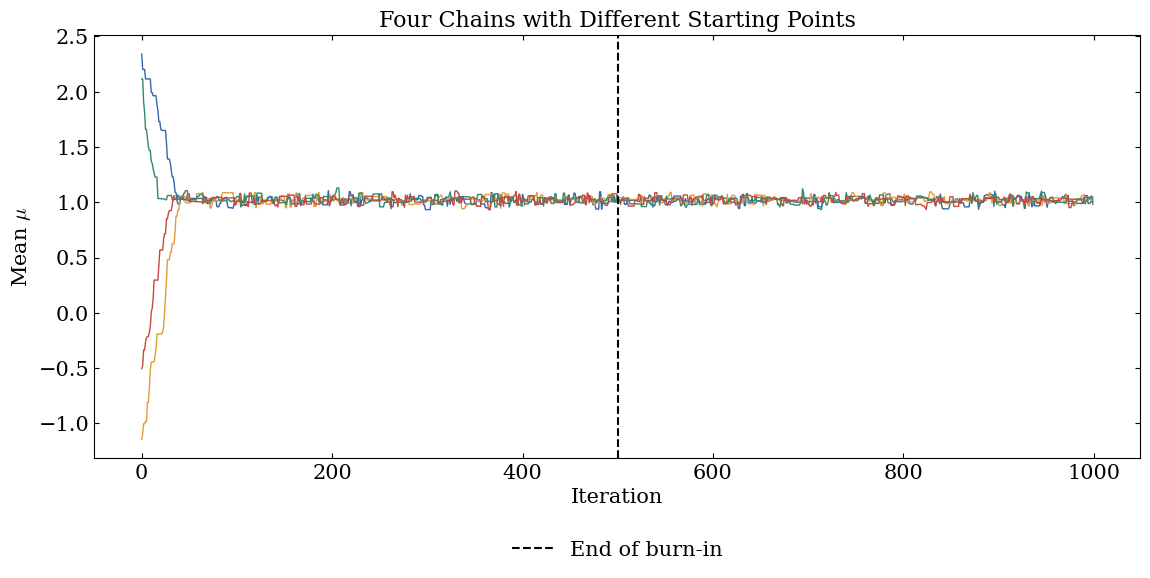

In [15]:
# Plot the first 1000 iterations of the four chains
plt.figure(figsize=(13.5, 5.5))
for chain in chains:
    plt.plot(chain[:1000], linewidth=1)

# Mark the end of the burn-in
plt.axvline(x=500, color='k', linestyle='--', linewidth=1.5, label='End of burn-in')
plt.xlabel('Iteration')
plt.ylabel('Mean $\\mu$')
plt.title('Four Chains with Different Starting Points')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.show()

The four chains start from different values and reach the same region within about 40 iterations, long before the end of the burn-in. The Gelman-Rubin statistic is close to 1, so they agree after the burn-in.

The Geweke test looks at parts of one chain, and the Gelman-Rubin diagnostic compares several chains. Together they indicate that the chain with the medium proposal width ($\nu = 0.1$) has converged. Both tests ask whether the chain has reached the posterior. They do not ask how many independent samples the chain holds, which is the question of the ESS. The chain with $\nu = 0.5$ shows the difference, because it passes the Geweke test but has a much lower ESS than the medium chain. We therefore use both kinds of check.

### Posterior Analysis

We have now checked the convergence and the efficiency of the chains. We continue with the chain of the medium proposal width, which has the largest ESS. We remove the burn-in and summarize the remaining samples with the posterior mean, the standard deviation and the 95 percent interval.

In [16]:
# Select the chain with the medium proposal width
chain = results[0.1][0]

# Discard the first 500 samples as burn-in
burn_in = 500
chain_post_burnin = chain[burn_in:]

# Calculate the 95% interval
ci_low = np.percentile(chain_post_burnin, 2.5)
ci_high = np.percentile(chain_post_burnin, 97.5)

# Print the summary statistics
print(f"Posterior mean = {np.mean(chain_post_burnin):.3f}")
print(f"Posterior standard deviation = {np.std(chain_post_burnin):.3f}")
print(f"95% interval = [{ci_low:.3f}, {ci_high:.3f}]")

Posterior mean = 1.019
Posterior standard deviation = 0.032
95% interval = [0.956, 1.078]


The histogram shows the posterior samples. A bar marks the 95 percent interval, and two lines mark the posterior mean and the true mean. The black curve is the normal distribution with the sample mean as its mean and the variance $1/1000$. It is the posterior that the likelihood alone gives, which is the posterior for a flat prior. Our Cauchy prior is broad and nearly flat over the range of the histogram, so it changes this curve very little.

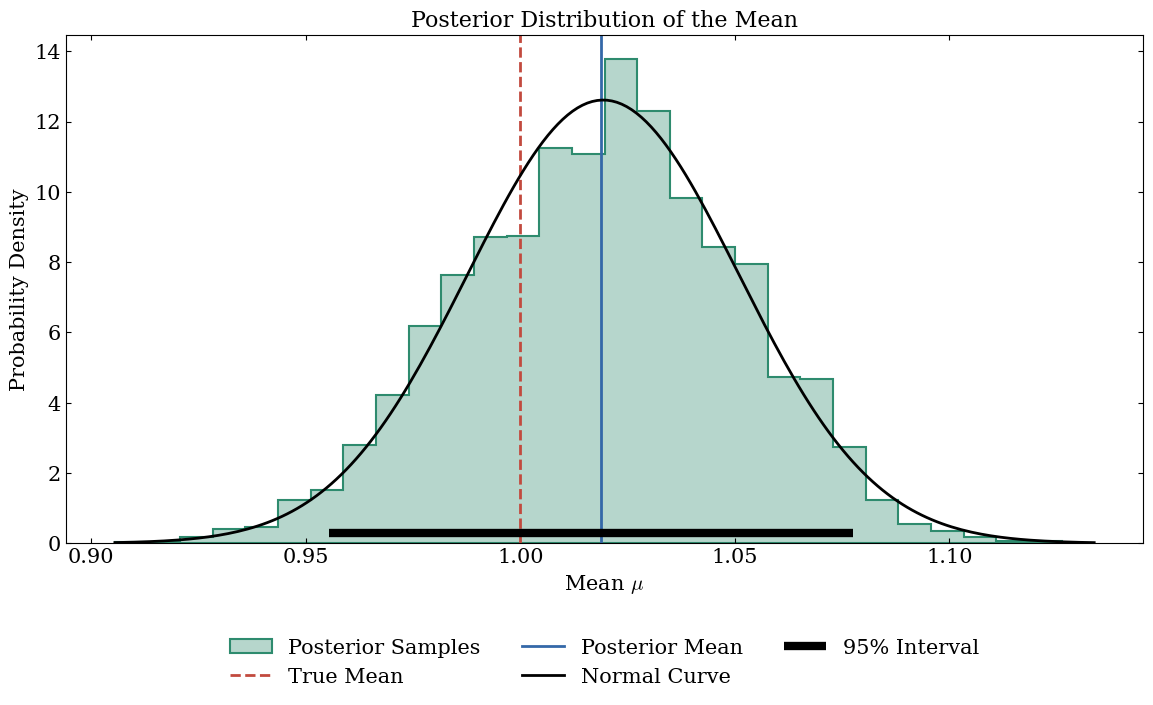

In [17]:
# Create a histogram of the posterior
plt.figure(figsize=(13.9, 6.6))
plt.hist(chain_post_burnin, bins=30, density=True, label='Posterior Samples',
         histtype='stepfilled', facecolor=('C2', 0.35), edgecolor='C2', linewidth=1.5)
plt.axvline(x=loc_true, color='C3', linestyle='--', linewidth=2, label='True Mean')
plt.axvline(x=np.mean(chain_post_burnin), color='C0', linewidth=2, label='Posterior Mean')

# Plot the normal distribution with the sample mean and the variance 1/n
mu_grid = np.linspace(np.min(chain_post_burnin), np.max(chain_post_burnin), 200)
plt.plot(mu_grid, np.exp(-0.5 * ((mu_grid - np.mean(x_sample)) * np.sqrt(n)) ** 2) / np.sqrt(2 * np.pi / n), color='black',
         linewidth=2, label='Normal Curve')

# Mark the 95% interval with a bar at the bottom of the plot
plt.plot([ci_low, ci_high], [0.3, 0.3], color='black', linewidth=6, solid_capstyle='butt',
         label='95% Interval')

# Add labels and title
plt.xlabel('Mean $\\mu$')
plt.ylabel('Probability Density')
plt.title('Posterior Distribution of the Mean')
plt.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))
plt.show()

### Reading the Posterior Distribution

We read three results from the posterior distribution.

1. **True mean.** The true mean lies inside the 95 percent interval, so the sampler recovers the parameter. The posterior mean is close to the sample mean, as we expected.
2. **Uncertainty.** The posterior standard deviation agrees with the standard error of the mean, $1/\sqrt{1000}$ (Section 3.6). This is the sampling noise of the average of 1000 measurements. The histogram follows the normal curve, so the 1000 measurements dominate the broad Cauchy prior.
3. **Posterior interval.** The 95 percent interval has a direct probabilistic meaning. Given our data and prior, we believe that $\mu$ lies in this range with a probability of 95 percent.

The posterior has no standard form, because the Cauchy prior is not conjugate to the normal likelihood (Section 5.2). MCMC does not need one, since it needs the posterior only up to a constant. It therefore also works for models whose posterior has no closed form. For one parameter, a grid would work as well (Chapter 12). The cost of a grid grows exponentially with the number of parameters, so MCMC becomes the practical choice.

### Thinning the Chain

The posterior summary used every sample of the chain. Many practitioners instead thin a chain, to reduce its autocorrelation and its storage, so we check what thinning does to the ESS. Thinning keeps only every $m$-th sample of a chain, so that the kept samples are less correlated (Section 13.12). We test it on the medium chain with $m = 10$. We compare the number of samples and the ESS of the full chain after the burn-in with those of the thinned chain.

In [18]:
# Keep every 10th sample of the medium chain after the burn-in
thinned_chain = chain_post_burnin[::10]

# Compare the number of samples and the ESS of the full and the thinned chain
print(f"Full chain: {len(chain_post_burnin)} samples, ESS = {calculate_ess(chain_post_burnin):.1f}")
print(f"Thinned chain: {len(thinned_chain)} samples, ESS = {calculate_ess(thinned_chain):.1f}")

Full chain: 9501 samples, ESS = 1978.6
Thinned chain: 951 samples, ESS = 830.9


The thinned chain needs 10 times less storage, but its ESS is about 2.4 times lower. This is the trade-off of thinning. Each kept sample carries more information, because it is less correlated with its neighbors, but we keep far fewer samples. The removed samples still carried information, so thinning lowers the ESS. We therefore keep every sample for the posterior summary and thin a chain only when storage requires it (Section 13.12).

## Gibbs Sampling

The Metropolis algorithm treats the parameters as one unit and needs a proposal distribution, whose width we had to tune. Gibbs sampling instead updates one parameter at a time, so it needs two or more parameters and no proposal width. It applies when we can draw each parameter from its conditional distribution given the others (Section 13.15).

### The Intuition Behind Gibbs Sampling

The idea is to replace one hard draw from the joint distribution by several easy draws from conditional distributions. Gibbs sampling works in three steps.

1. Update one parameter at a time and hold the others fixed.
2. Sample the new value directly from the conditional distribution of this parameter.
3. Cycle through all parameters in turn.

It is useful when the conditional distributions have known forms that are easy to sample. Gibbs sampling accepts every new value, because it samples from the exact conditional distributions. It is a special case of the Metropolis-Hastings algorithm with an acceptance probability of 1 (Section 13.15).

### Sampling from a Bivariate Gaussian Distribution

We illustrate Gibbs sampling with a bivariate Gaussian distribution. We can write down the conditional distributions of this example in closed form. The example shows how the correlation of the parameters affects the sampling efficiency. We sample from a bivariate Gaussian distribution with zero mean and correlation coefficient $\rho$,

$$\begin{pmatrix} x_1 \\ x_2 \end{pmatrix} \sim \mathcal{N}\left(\mathbf{0}, \begin{bmatrix} 1 & \rho \\ \rho & 1 \end{bmatrix}\right).$$

Gibbs sampling needs the conditional distributions $p(x_1 | x_2)$ and $p(x_2 | x_1)$. For a bivariate Gaussian distribution, they are also Gaussian (Section 5.9),

$$p(x_1 | x_2) = \mathcal{N}(\rho x_2, 1-\rho^2),$$

$$p(x_2 | x_1) = \mathcal{N}(\rho x_1, 1-\rho^2).$$

The conditional mean depends linearly on the conditioning variable and scales with $\rho$. The conditional variance $1-\rho^2$ decreases as the correlation increases. For $\rho = 0$, both conditional distributions are $\mathcal{N}(0, 1)$.

The Gibbs sampler alternates between two steps.

1. Sample $x_1^{(t+1)} \sim \mathcal{N}(\rho x_2^{(t)}, 1-\rho^2)$.
2. Sample $x_2^{(t+1)} \sim \mathcal{N}(\rho x_1^{(t+1)}, 1-\rho^2)$.

In [19]:
def gibbs_sampler(n_samples, rho):
    """Draw samples of a bivariate Gaussian with unit variances and correlation rho by Gibbs sampling."""

    # Initialize the storage for the samples
    samples = np.zeros((n_samples, 2))

    # Start far from the center of the distribution to show the burn-in
    x1 = 100
    x2 = 100

    # Run the Gibbs sampler
    for i in range(n_samples):
        # Sample x1 from its conditional distribution given x2, N(rho*x2, 1-rho^2)
        x1 = np.random.normal(loc=rho*x2, scale=np.sqrt(1-rho**2))

        # Sample x2 from its conditional distribution given x1, N(rho*x1, 1-rho^2)
        x2 = np.random.normal(loc=rho*x1, scale=np.sqrt(1-rho**2))

        # Store the sample
        samples[i, :] = [x1, x2]

    return samples

The function returns one row per iteration with the values of $x_1$ and $x_2$.

### Impact of Correlation on Gibbs Sampling Efficiency

We now study how the correlation coefficient affects the efficiency of Gibbs sampling. Strong correlations are common in astronomical models, so we compare a strong correlation, $\rho = 0.95$, with a weak correlation, $\rho = 0.1$. The conditional distributions of the two runs differ only through $\rho$, so any difference in the efficiency comes from the correlation. Each run has 10,000 iterations and starts at $x_1 = x_2 = 100$, far from the distribution. We start there and discard the first 100 iterations as burn-in.

In [20]:
# Run Gibbs sampling for the strong and the weak correlation
n_samples = 10000
rhos = [0.95, 0.1]
samples = {rho: gibbs_sampler(n_samples, rho) for rho in rhos}

We first plot the samples after the burn-in as dots, with the contours of the true distribution. The dots overlap where the samples are dense.

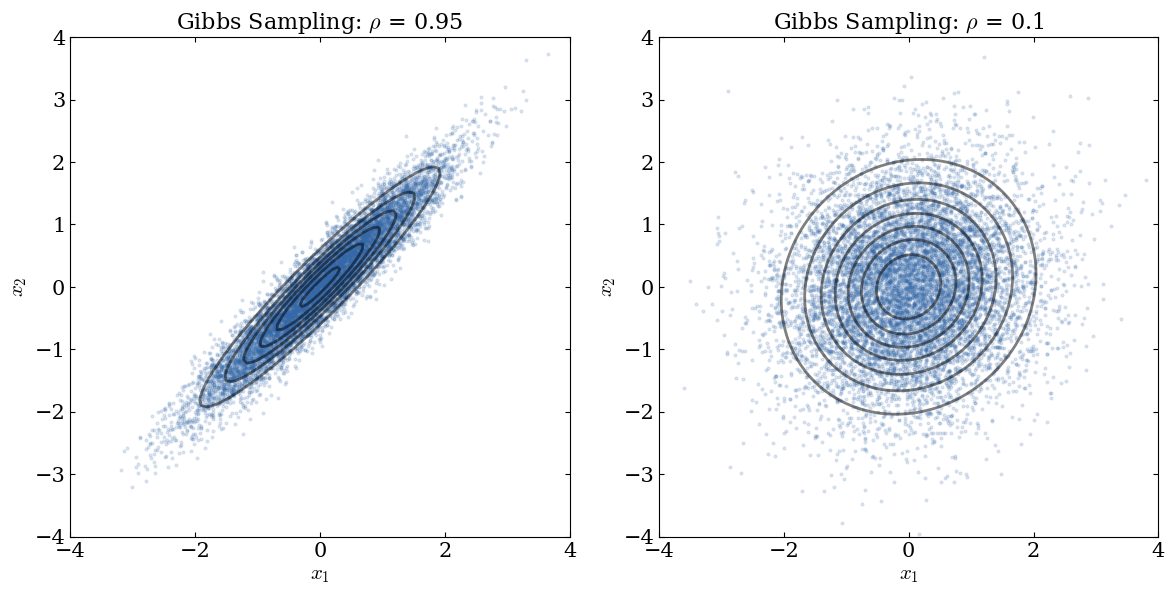

In [21]:
# Grid of positions for the contours of the true distribution
x = np.linspace(-4, 4, 100)
X, Y = np.meshgrid(x, x)

# Create a figure with one panel for each correlation
fig, axes = plt.subplots(1, 2, figsize=(12, 6))
for ax, rho in zip(axes, rhos):
    # Plot the samples after the burn-in
    s = samples[rho][100:]
    ax.scatter(s[:, 0], s[:, 1], alpha=0.15, s=4)

    # Plot the contours of the true bivariate normal distribution
    density = np.exp(-(X**2 - 2 * rho * X * Y + Y**2) / (2 * (1 - rho**2))) / (2 * np.pi * np.sqrt(1 - rho**2))
    ax.contour(X, Y, density, colors='k', alpha=0.5, linewidths=2)

    # Labels and title
    ax.set_xlim(-4, 4)
    ax.set_ylim(-4, 4)
    ax.set_aspect('equal')
    ax.set_xlabel('$x_1$')
    ax.set_ylabel('$x_2$')
    ax.set_title(f'Gibbs Sampling: $\\rho$ = {rho}')

plt.tight_layout()
plt.show()

The dots are the samples and the black contours show the true distribution. In both panels the samples fill the contours, so the sampler reproduces the true distribution for both correlations. For $\rho = 0.95$, the distribution is highly stretched along the diagonal, which creates a ridge. Gibbs sampling moves along one axis at a time, like a climber on a narrow diagonal ridge who can move only north-south or east-west. It must therefore follow the ridge in small steps. For $\rho = 0.1$, the distribution is nearly circular, so the updates along the axes fit its shape.

A scatter plot hides the order of the samples. We therefore plot the variables against the iteration for the first 100 iterations, which show the burn-in, and for the 100 iterations after them.

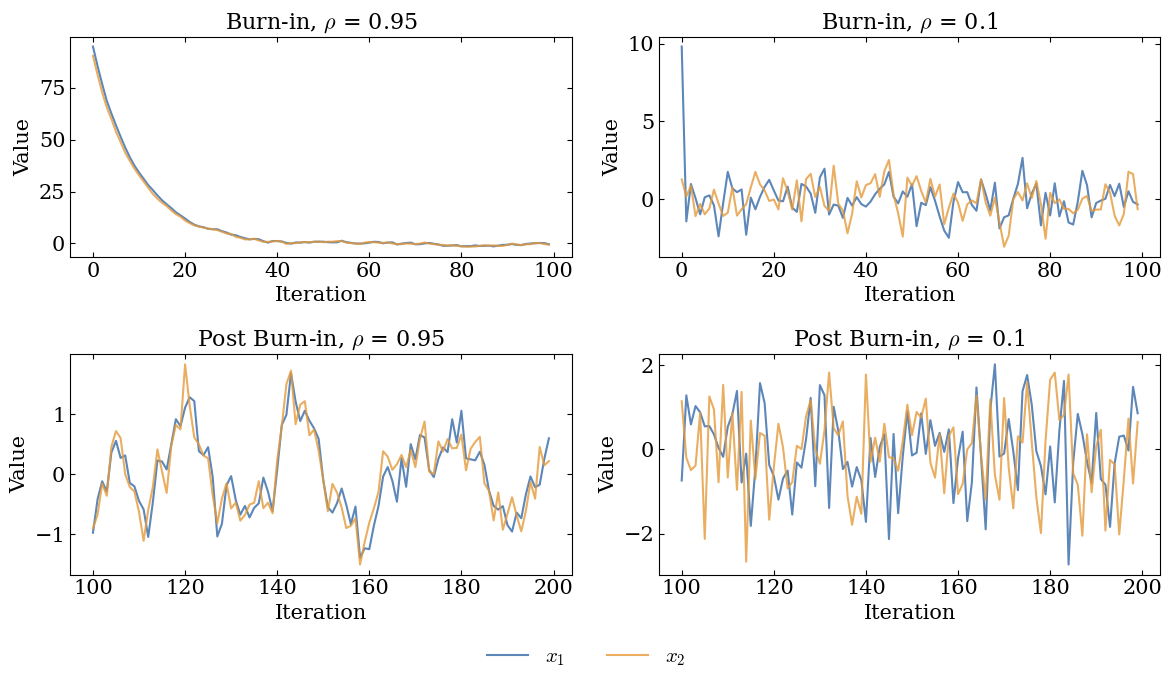

In [22]:
# Create a figure with the burn-in in the top row and the next 100 iterations in the bottom row
fig, axes = plt.subplots(2, 2, figsize=(12, 7))
for col, rho in enumerate(rhos):
    for row, (start, end) in enumerate([(0, 100), (100, 200)]):
        ax = axes[row, col]

        # Plot x1 and x2 against the iteration
        iterations = np.arange(start, end)
        ax.plot(iterations, samples[rho][start:end, 0], label='$x_1$', alpha=0.8)
        ax.plot(iterations, samples[rho][start:end, 1], label='$x_2$', alpha=0.8)

        # Labels and title
        ax.set_xlabel('Iteration')
        ax.set_ylabel('Value')
        ax.set_title(f"{'Burn-in' if row == 0 else 'Post Burn-in'}, $\\rho$ = {rho}")

# One legend below the panels
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=2)
plt.tight_layout(rect=(0, 0.06, 1, 1))
plt.show()

For $\rho = 0.95$, the chain needs tens of iterations to leave its starting point. Afterwards both variables change slowly, with long excursions in one direction before they reverse. The conditional variance $1 - \rho^2$ is small, so each step is short and the chain needs many iterations to cross the distribution.

For $\rho = 0.1$, the chain leaves its starting point in one iteration. Both variables then fluctuate quickly between positive and negative values. The conditional variance is close to 1, so the steps are large. In both cases the first 100 iterations cover the burn-in.

### Autocorrelation Analysis: Measuring Sampling Efficiency

The traces suggest that the high correlation lowers the efficiency. We measure this with the autocorrelation of $x_1$ after the burn-in and its ESS. We show $x_1$ only, because $x_2$ behaves in the same way by symmetry.

For this sampler we can also derive the autocorrelation exactly, which lets us check our estimate. One iteration draws $x_2$ with the mean $\rho x_1$ and then draws the new $x_1$ with the mean $\rho x_2$. The new $x_1$ therefore keeps the fraction $\rho^2$ of the old $x_1$ and adds independent noise. After $k$ iterations the fraction is $\rho^{2k}$, so $R(k) = \rho^{2k}$. In the ESS formula, the geometric series $1 + 2\sum_{k=1}^{\infty}R(k)$ then equals $(1+\rho^2)/(1-\rho^2)$, so the ESS is

$$\text{ESS} = \frac{N(1-\rho^2)}{1+\rho^2}.$$

We plot the estimated and the exact autocorrelation, with the same red band as before, and give both ESS values.

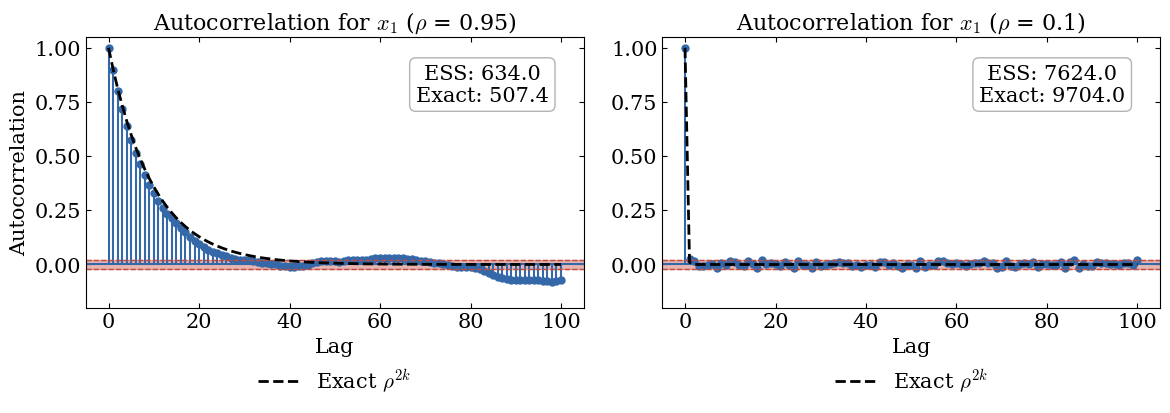

In [23]:
# Create a figure for the autocorrelation plots
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
lags = np.arange(101)
for ax, rho in zip(axes, rhos):
    # Extract the samples of x1 after the burn-in
    x1 = samples[rho][100:, 0]

    # Plot the autocorrelation of x1
    plot_autocorrelation(x1, 100, ax)

    # Plot the exact autocorrelation rho^(2k)
    ax.plot(lags, rho**(2 * lags), color='black', linestyle='--', linewidth=2, label='Exact $\\rho^{2k}$')
    ax.set_ylim(-0.2, 1.05)
    ax.set_title(f"Autocorrelation for $x_1$ ($\\rho$ = {rho})")
    ax.set_xlabel("Lag")
    ax.legend(ncol=3, loc='upper center', bbox_to_anchor=(0.5, -0.15))

    # Calculate the effective sample size and its exact value
    ess = calculate_ess(x1)
    ess_exact = len(x1) * (1 - rho**2) / (1 + rho**2)
    ax.text(0.93, 0.9, f"ESS: {ess:.1f}\nExact: {ess_exact:.1f}", ha='right', va='top', multialignment='center', transform=ax.transAxes,
            bbox=dict(boxstyle="round,pad=0.3", facecolor="white", edgecolor="0.7"))

axes[0].set_ylabel("Autocorrelation")
plt.tight_layout()
plt.show()

In both panels, the estimated autocorrelation follows the dashed curve $R(k) = \rho^{2k}$ that we derived above, so the estimate agrees with the exact result.

For $\rho = 0.95$, the autocorrelation decays slowly. Samples many iterations apart still share information, so the ESS is far below the number of samples. At large lags the estimate scatters around the curve and dips below zero. This is sampling noise.

For $\rho = 0.1$, the curve is already close to zero at the first lag, so the chain mixes efficiently. The ESS is then of the order of the number of samples. In both panels, the estimated ESS differs somewhat from the exact value, because it sums noisy estimates of the autocorrelation up to lag 100.

In the Metropolis runs, the acceptance rate warned us about a badly tuned width. Here it is 1 in both runs, because Gibbs sampling accepts every draw, so only the ESS shows the difference. The inefficiency comes from updating one variable at a time while the variables have a high correlation.

The remedy is block Gibbs sampling (Section 13.15), a divide and conquer strategy. We group the highly correlated parameters into blocks, so that different blocks are only weakly correlated with each other. We then update one block at a time given the others. Within a block, we draw from the joint conditional distribution when we can. Otherwise we use another sampler for that block, such as the Metropolis algorithm with a proposal that follows the correlation inside the block.

## Summary

In this tutorial we sampled a posterior with two basic MCMC algorithms, the Metropolis algorithm and Gibbs sampling. We also judged the quality of the chains. Our main lessons follow.

1. **The Metropolis algorithm.** It samples a posterior that we know only up to a constant, because it needs only ratios of posterior values. A step to a higher posterior is always accepted, and a step to a lower posterior is accepted with the ratio as its probability.
2. **The proposal width.** A narrow proposal gives a high acceptance rate but slow motion. A wide proposal gives many rejections and repeated values. The acceptance rate is a first guide for tuning, and the ESS measures the result.
3. **Autocorrelation and the ESS.** Successive samples of a chain are correlated. The ESS counts the independent samples that carry the same information, so we judge a chain by its ESS and not by its length.
4. **Thinning.** Keeping every $m$-th sample saves storage but lowers the ESS, because the removed samples still carry information. We thin a chain only when storage requires it.
5. **Burn-in and convergence.** A chain starts where we choose, so we discard the burn-in. The Geweke test compares two parts of one chain, and the Gelman-Rubin diagnostic compares several chains from different starting points. Neither counts independent samples.
6. **Gibbs sampling.** It samples each parameter from its conditional distribution given the others, accepts every draw and does not need a proposal width. It is useful when the conditional distributions are simple, for example in hierarchical models. A high correlation between parameters makes one-at-a-time updates inefficient. We then divide the parameters into blocks of correlated parameters and update each block with Gibbs sampling or another sampler.

MCMC lets us sample distributions that we cannot sample directly, in particular the posteriors of inference problems in astronomy. These posteriors are known only up to a constant and often have no closed form. They may also have many parameters, where rejection and importance sampling become inefficient (Chapter 12). A chain whose stationary distribution is the posterior replaces direct sampling with a sequence of local steps.